# Retail Sales Profitability Analysis
## Where does a US retailer actually make money — and where do discounts destroy it?

**A portfolio project by Youssef Mamdouh** | Data Analysis with Python (Pandas, Matplotlib, Seaborn)

---

### Business context
A US office-supply and furniture retailer wants to know why **profit growth lags sales growth**.
Leadership suspects aggressive discounting is quietly eroding margins, but no one has quantified
where the damage happens — which products, which regions, and at what discount depth.

### Questions this analysis answers
1. **Trend** — How do sales and profit evolve over time? Is the business seasonally healthy?
2. **Product mix** — Which categories and sub-categories earn money, and which consistently lose it?
3. **Geography** — Which regions underperform, and is the problem local or systemic?
4. **The discount dilemma** — At what discount level does an average order line stop being profitable?
5. **Customers & operations** — Which customer segments and shipping modes are the most profitable?

### Dataset
**Sample Superstore** — Tableau's public sample dataset (fictionalized US retail data released for
educational use). 9,994 order lines covering 2014–2017, with order, product, customer, geography,
discount and profit fields. Source and license details are in the project README.

> **Provenance note:** this is Tableau's fictional sample data, not real company records. The
> cleaning, analysis and findings below are my own work on that dataset.


## 1. Setup

In [1]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# ---- style ---------------------------------------------------------------
sns.set_theme(style="whitegrid", font_scale=1.05)
plt.rcParams.update({
    "figure.dpi": 110,
    "axes.titlesize": 13,
    "axes.titleweight": "bold",
    "axes.labelcolor": "#374151",
    "text.color": "#1F2937",
    "axes.edgecolor": "#D1D5DB",
})

C_SALES = "#2A6FBB"   # blue   - sales
C_PROFIT = "#E8833A"  # orange - profit
C_POS = "#2E8B57"     # green  - positive
C_NEG = "#C0392B"     # red    - losses

DATA = Path("../data/superstore.csv")
FIG = Path("../figures")
FIG.mkdir(exist_ok=True)

def save(fig, name):
    fig.savefig(FIG / name, bbox_inches="tight")
    print(f"saved figures/{name}")


## 2. Load and first look

In [2]:
df = pd.read_csv(DATA)
# dates are US-style M/D/YYYY with mixed zero-padding
for col in ["Order Date", "Ship Date"]:
    df[col] = pd.to_datetime(df[col], format="mixed", dayfirst=False)

print(f"Shape: {df.shape[0]:,} rows x {df.shape[1]} columns")
df.head()


Shape: 9,994 rows x 21 columns


,Row ID,Order ID,Order Date,Ship Date,Ship Mode,Customer ID,Customer Name,Segment,Country,City,...,Postal Code,Region,Product ID,Category,Sub-Category,Product Name,Sales,Quantity,Discount,Profit
0,1,CA-2016-152156,2016-11-08,2016-11-11,Second Class,CG-12520,Claire Gute,Consumer,United States,Henderson,...,42420,South,FUR-BO-10001798,Furniture,Bookcases,Bush Somerset Collection Bookcase,261.9600,2,0.00,41.9136
1,2,CA-2016-152156,2016-11-08,2016-11-11,Second Class,CG-12520,Claire Gute,Consumer,United States,Henderson,...,42420,South,FUR-CH-10000454,Furniture,Chairs,"Hon Deluxe Fabric Upholstered Stacking Chairs,...",731.9400,3,0.00,219.5820
2,3,CA-2016-138688,2016-06-12,2016-06-16,Second Class,DV-13045,Darrin Van Huff,Corporate,United States,Los Angeles,...,90036,West,OFF-LA-10000240,Office Supplies,Labels,Self-Adhesive Address Labels for Typewriters b...,14.6200,2,0.00,6.8714
3,4,US-2015-108966,2015-10-11,2015-10-18,Standard Class,SO-20335,Sean O'Donnell,Consumer,United States,Fort Lauderdale,...,33311,South,FUR-TA-10000577,Furniture,Tables,Bretford CR4500 Series Slim Rectangular Table,957.5775,5,0.45,-383.0310
4,5,US-2015-108966,2015-10-11,2015-10-18,Standard Class,SO-20335,Sean O'Donnell,Consumer,United States,Fort Lauderdale,...,33311,South,OFF-ST-10000760,Office Supplies,Storage,Eldon Fold 'N Roll Cart System,22.3680,2,0.20,2.5164


In [3]:
df.info()


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 9994 entries, 0 to 9993
Data columns (total 21 columns):
 #   Column         Non-Null Count  Dtype         
---  ------         --------------  -----         
 0   Row ID         9994 non-null   int64         
 1   Order ID       9994 non-null   object        
 2   Order Date     9994 non-null   datetime64[ns]
 3   Ship Date      9994 non-null   datetime64[ns]
 4   Ship Mode      9994 non-null   object        
 5   Customer ID    9994 non-null   object        
 6   Customer Name  9994 non-null   object        
 7   Segment        9994 non-null   object        
 8   Country        9994 non-null   object        
 9   City           9994 non-null   object        
 10  State          9994 non-null   object        
 11  Postal Code    9994 non-null   int64         
 12  Region         9994 non-null   object        
 13  Product ID     9994 non-null   object        
 14  Category       9994 non-null   object        
 15  Sub-Category   9994 n

In [4]:
df.describe().round(2)


,Row ID,Order Date,Ship Date,Postal Code,Sales,Quantity,Discount,Profit
count,9994.00,9994,9994,9994.00,9994.00,9994.00,9994.00,9994.00
mean,4997.50,2016-04-30 00:07:12.259355648,2016-05-03 23:06:58.571142912,55190.38,229.86,3.79,0.16,28.66
min,1.00,2014-01-03 00:00:00,2014-01-07 00:00:00,1040.00,0.44,1.00,0.00,-6599.98
25%,2499.25,2015-05-23 00:00:00,2015-05-27 00:00:00,23223.00,17.28,2.00,0.00,1.73
50%,4997.50,2016-06-26 00:00:00,2016-06-29 00:00:00,56430.50,54.49,3.00,0.20,8.67
75%,7495.75,2017-05-14 00:00:00,2017-05-18 00:00:00,90008.00,209.94,5.00,0.20,29.36
max,9994.00,2017-12-30 00:00:00,2018-01-05 00:00:00,99301.00,22638.48,14.00,0.80,8399.98
std,2885.16,NaN,NaN,32063.69,623.25,2.23,0.21,234.26


## 3. Data cleaning and feature engineering

Checks performed:
- **Duplicates** — exact duplicate order lines
- **Missing values** — per column
- **Value ranges** — discount within [0, 1], dates parse correctly
- **New features** — `Order Year`, `Order Month`, `Profit Margin`, `Shipping Days`


In [5]:
# exact duplicates and missing values
print(f"Duplicate rows: {df.duplicated().sum()}")
print(f"Missing values: {int(df.isna().sum().sum())}")

# range sanity checks
assert df["Discount"].between(0, 1).all(), "discount outside [0, 1]"
assert (df["Ship Date"] >= df["Order Date"]).all(), "ship before order"
print("Range checks passed: discounts in [0, 1], ship date >= order date")

# Row ID is a pure index column - drop it
df = df.drop(columns=["Row ID"])

# feature engineering
df["Order Year"] = df["Order Date"].dt.year
df["Order Month"] = df["Order Date"].dt.to_period("M").dt.to_timestamp()
df["Profit Margin"] = np.where(df["Sales"] > 0, df["Profit"] / df["Sales"], np.nan)
df["Shipping Days"] = (df["Ship Date"] - df["Order Date"]).dt.days

print(f"\nDate range: {df['Order Date'].min():%b %Y} - {df['Order Date'].max():%b %Y}")
df.head(3)


Duplicate rows: 0
Missing values: 0
Range checks passed: discounts in [0, 1], ship date >= order date

Date range: Jan 2014 - Dec 2017


,Order ID,Order Date,Ship Date,Ship Mode,Customer ID,Customer Name,Segment,Country,City,State,...,Sub-Category,Product Name,Sales,Quantity,Discount,Profit,Order Year,Order Month,Profit Margin,Shipping Days
0,CA-2016-152156,2016-11-08,2016-11-11,Second Class,CG-12520,Claire Gute,Consumer,United States,Henderson,Kentucky,...,Bookcases,Bush Somerset Collection Bookcase,261.96,2,0.0,41.9136,2016,2016-11-01,0.16,3
1,CA-2016-152156,2016-11-08,2016-11-11,Second Class,CG-12520,Claire Gute,Consumer,United States,Henderson,Kentucky,...,Chairs,"Hon Deluxe Fabric Upholstered Stacking Chairs,...",731.94,3,0.0,219.5820,2016,2016-11-01,0.30,3
2,CA-2016-138688,2016-06-12,2016-06-16,Second Class,DV-13045,Darrin Van Huff,Corporate,United States,Los Angeles,California,...,Labels,Self-Adhesive Address Labels for Typewriters b...,14.62,2,0.0,6.8714,2016,2016-06-01,0.47,4


## 4. Business overview

Headline numbers before digging in.

In [6]:
kpis = {
    "Total sales": f"${df['Sales'].sum():,.0f}",
    "Total profit": f"${df['Profit'].sum():,.0f}",
    "Overall profit margin": f"{df['Profit'].sum() / df['Sales'].sum() * 100:.1f}%",
    "Orders": f"{df['Order ID'].nunique():,}",
    "Order lines": f"{len(df):,}",
    "Unique customers": f"{df['Customer ID'].nunique():,}",
    "Unique products": f"{df['Product ID'].nunique():,}",
    "Average discount given": f"{df['Discount'].mean() * 100:.1f}%",
}
pd.Series(kpis, name="Value").to_frame()


,Value
Total sales,"$2,297,201"
Total profit,"$286,397"
Overall profit margin,12.5%
Orders,"5,009"
Order lines,"9,994"
Unique customers,793
Unique products,"1,862"
Average discount given,15.6%


## 5. Question 1 — How do sales and profit trend over time?

Quarterly aggregation smooths month-to-month noise and shows the underlying pattern.

saved figures/fig1_quarterly_trend.png


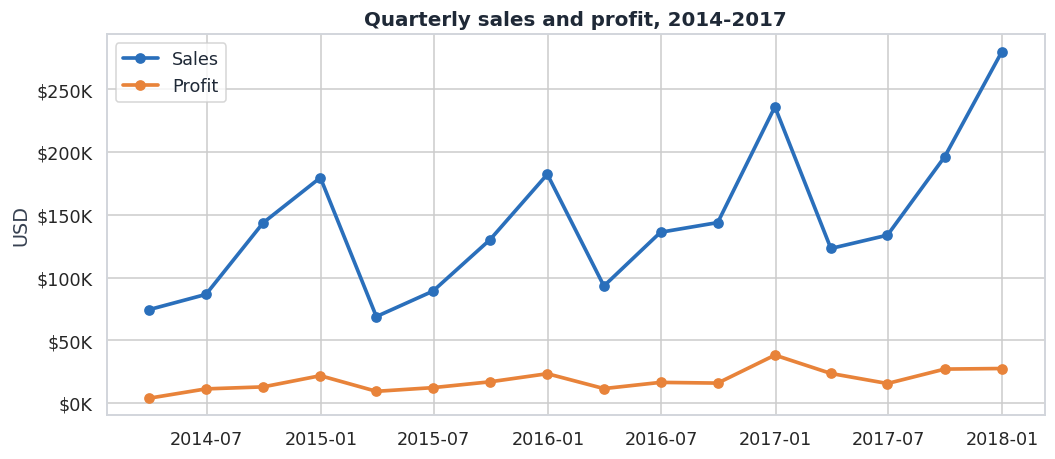

,Sales,Profit,Sales YoY %,Profit YoY %
Order Year,,,,
2014,484247.5,49544.0,NaN,NaN
2015,470532.5,61618.6,-2.8,24.4
2016,609205.6,81795.2,29.5,32.7
2017,733215.3,93439.3,20.4,14.2


In [7]:
quarterly = (df.set_index("Order Date")
               .resample("QE")[["Sales", "Profit"]].sum())

fig, ax = plt.subplots(figsize=(11, 4.5))
ax.plot(quarterly.index, quarterly["Sales"], color=C_SALES, lw=2.4,
        marker="o", label="Sales")
ax.plot(quarterly.index, quarterly["Profit"], color=C_PROFIT, lw=2.4,
        marker="o", label="Profit")
ax.set_title("Quarterly sales and profit, 2014-2017")
ax.set_ylabel("USD")
ax.yaxis.set_major_formatter(lambda v, p: f"${v/1000:,.0f}K")
ax.legend()
save(fig, "fig1_quarterly_trend.png")
plt.show()

growth = df.groupby("Order Year")[["Sales", "Profit"]].sum()
growth["Sales YoY %"] = growth["Sales"].pct_change() * 100
growth["Profit YoY %"] = growth["Profit"].pct_change() * 100
growth.round(1)


**Insight 1 — Strong seasonality, and profit growth lags sales growth.**
Every year ends with a sharp Q4 peak (holiday season) and a soft Q1. Sales dip slightly in 2015
(-2.8%), then grow strongly (+29.5% in 2016, +20.4% in 2017). Profit grows every year, but in 2017
it grows only +14.2% against +20.4% sales — the faster the business scales, the more margin quality
erodes. The discount analysis in section 8 shows where that erosion comes from.


## 6. Question 2 — Which products earn money, and which lose it?

saved figures/fig2_category_sales_profit.png


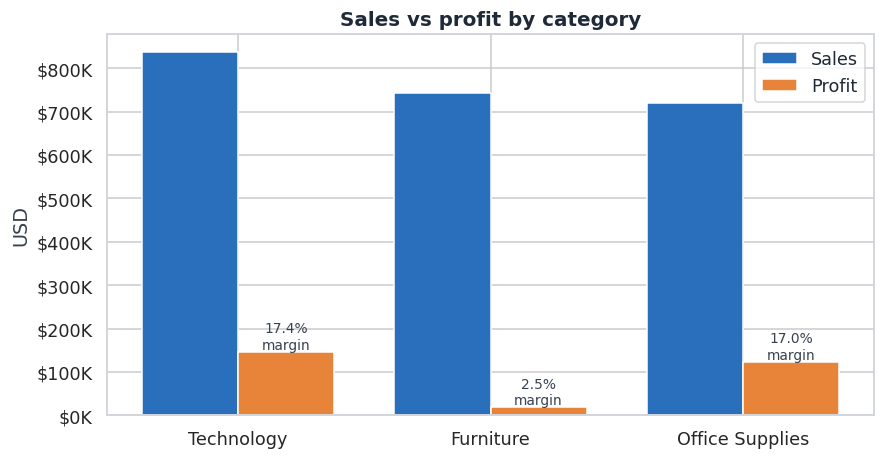

,Sales,Profit,Margin %
Category,,,
Technology,836154.0,145454.9,17.4
Furniture,741999.8,18451.3,2.5
Office Supplies,719047.0,122490.8,17.0


In [8]:
cat = (df.groupby("Category")[["Sales", "Profit"]].sum()
         .sort_values("Sales", ascending=False))
cat["Margin %"] = cat["Profit"] / cat["Sales"] * 100

fig, ax = plt.subplots(figsize=(9, 4.5))
x = np.arange(len(cat))
w = 0.38
ax.bar(x - w/2, cat["Sales"], width=w, color=C_SALES, label="Sales")
ax.bar(x + w/2, cat["Profit"], width=w, color=C_PROFIT, label="Profit")
ax.set_xticks(x, cat.index)
ax.set_title("Sales vs profit by category")
ax.set_ylabel("USD")
ax.yaxis.set_major_formatter(lambda v, p: f"${v/1000:,.0f}K")
ax.legend()
for i, m in enumerate(cat["Margin %"]):
    ax.text(i + w/2, cat["Profit"].iloc[i] + 8000, f"{m:.1f}%\nmargin",
            ha="center", fontsize=9, color="#374151")
save(fig, "fig2_category_sales_profit.png")
plt.show()

cat.round(1)


saved figures/fig3_subcategory_profit.png


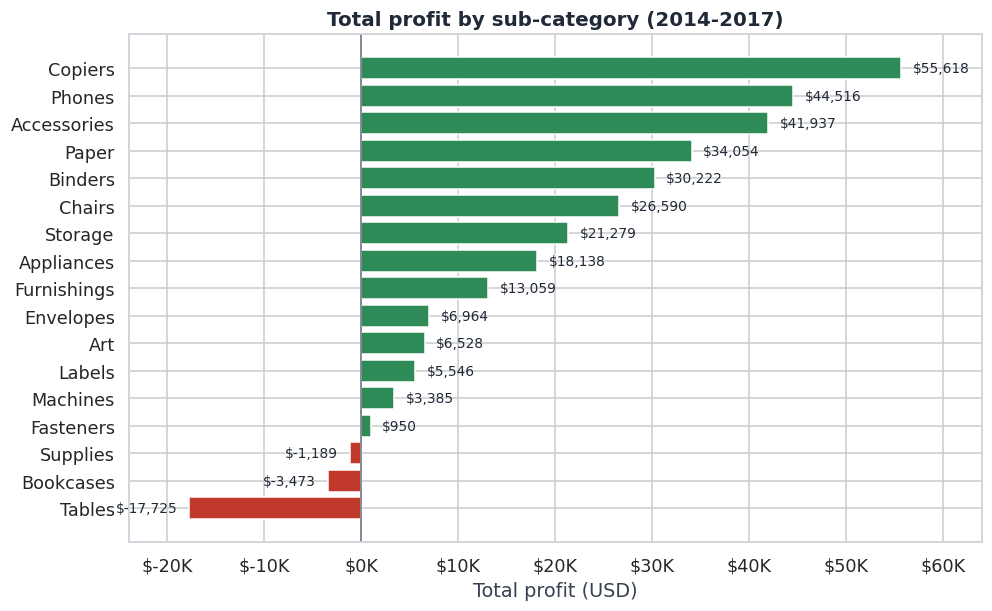

Sub-categories that LOST money over 4 years:
                 Sales   Profit
Sub-Category                   
Tables        206966.0 -17725.0
Bookcases     114880.0  -3473.0
Supplies       46674.0  -1189.0


In [9]:
sub = (df.groupby("Sub-Category")[["Sales", "Profit"]].sum()
         .sort_values("Profit"))

fig, ax = plt.subplots(figsize=(10, 6))
colors = [C_NEG if p < 0 else C_POS for p in sub["Profit"]]
ax.barh(sub.index, sub["Profit"], color=colors)
ax.axvline(0, color="#6B7280", lw=1)
ax.set_title("Total profit by sub-category (2014-2017)")
ax.set_xlabel("Total profit (USD)")
ax.xaxis.set_major_formatter(lambda v, p: f"${v/1000:,.0f}K")
for y, v in enumerate(sub["Profit"]):
    ax.text(v + (1200 if v >= 0 else -1200), y, f"${v:,.0f}",
            va="center", ha="left" if v >= 0 else "right", fontsize=9)
ax.set_xlim(sub["Profit"].min() * 1.35, sub["Profit"].max() * 1.15)
save(fig, "fig3_subcategory_profit.png")
plt.show()

losers = sub[sub["Profit"] < 0]
print("Sub-categories that LOST money over 4 years:")
print(losers.round(0))


**Insight 2 — The product mix hides real losers.**
Technology (17.4% margin) and Office Supplies (17.0%) are the profit engines, led by Copiers,
Phones, Accessories and Paper. Furniture sells almost as much as Technology but keeps only a 2.5%
margin. **Tables (-$17.7K) and Bookcases (-$3.5K) have lost money cumulatively over four years** —
these are not bad quarters, they are structurally unprofitable lines. Supplies and Fasteners sit at
break-even. A portfolio this size should not carry sub-categories that never turn a profit.


## 7. Question 3 — Which regions underperform?

saved figures/fig4_region_margins.png


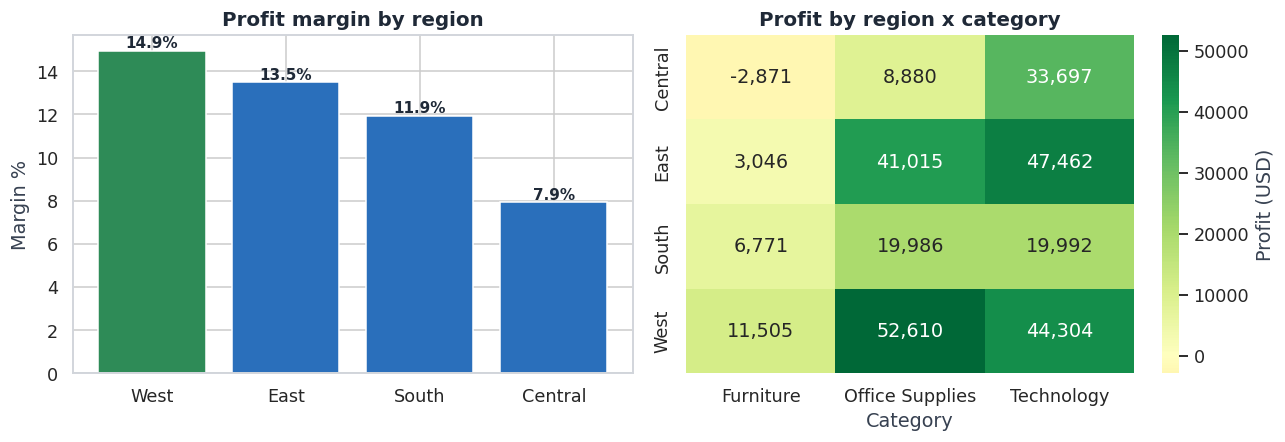

,Sales,Profit,Margin %
Region,,,
West,725457.8,108418.4,14.9
East,678781.2,91522.8,13.5
South,391721.9,46749.4,11.9
Central,501239.9,39706.4,7.9


In [10]:
region = (df.groupby("Region")[["Sales", "Profit"]].sum()
            .sort_values("Profit", ascending=False))
region["Margin %"] = region["Profit"] / region["Sales"] * 100

fig, axes = plt.subplots(1, 2, figsize=(12, 4.2))
axes[0].bar(region.index, region["Margin %"],
            color=[C_POS if m == region["Margin %"].max() else C_SALES for m in region["Margin %"]])
axes[0].set_title("Profit margin by region")
axes[0].set_ylabel("Margin %")
for i, m in enumerate(region["Margin %"]):
    axes[0].text(i, m + 0.15, f"{m:.1f}%", ha="center", fontsize=10, fontweight="bold")

pivot = df.pivot_table(index="Region", columns="Category", values="Profit",
                       aggfunc="sum").round(0)
sns.heatmap(pivot, annot=True, fmt=",.0f", cmap="RdYlGn", center=0, ax=axes[1],
            cbar_kws={"label": "Profit (USD)"})
axes[1].set_title("Profit by region x category")
axes[1].set_ylabel("")
fig.tight_layout()
save(fig, "fig4_region_margins.png")
plt.show()

region.round(1)


**Insight 3 — The Central region has a Furniture problem, not a demand problem.**
The West (14.9% margin) and East (13.5%) are comfortably profitable; Central trails at 7.9%. The
heatmap shows why: Central's Furniture cell is the only one in the red (-$2.9K), while its
Technology business (+$33.7K) is healthy. The fix is targeted — pricing and discount discipline in
Central Furniture — rather than a national overhaul.


## 8. Question 4 — The discount dilemma: when does a discount stop paying for itself?

This is the core question. Two views: every order line as a point, then average profit and margin
per discount band.

saved figures/fig5_discount_scatter.png


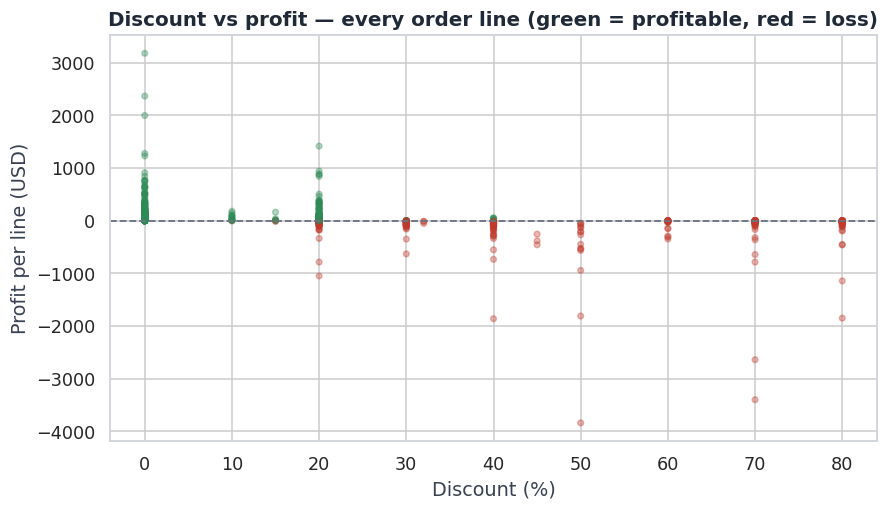

In [11]:
fig, ax = plt.subplots(figsize=(9, 4.8))
sample = df.sample(2000, random_state=42)
colors = np.where(sample["Profit"] >= 0, C_POS, C_NEG)
ax.scatter(sample["Discount"] * 100, sample["Profit"], c=colors, alpha=0.35, s=14)
ax.axhline(0, color="#6B7280", lw=1.2, ls="--")
ax.set_title("Discount vs profit — every order line (green = profitable, red = loss)")
ax.set_xlabel("Discount (%)")
ax.set_ylabel("Profit per line (USD)")
save(fig, "fig5_discount_scatter.png")
plt.show()


saved figures/fig6_discount_bands.png


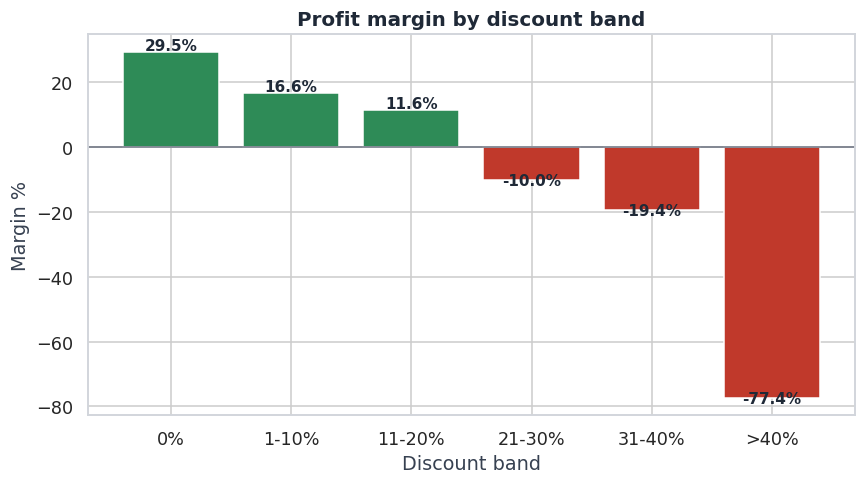

,lines,avg_profit,total_profit,sales,margin %
Discount,,,,,
0%,4798,66.9,320987.6,1087908.5,29.5
1-10%,94,96.1,9029.2,54369.4,16.6
11-20%,3709,24.7,91756.3,792152.9,11.6
21-30%,227,-45.7,-10369.3,103226.7,-10.0
31-40%,233,-109.2,-25448.2,130911.2,-19.4
>40%,933,-106.7,-99558.6,128632.3,-77.4


In [12]:
bands = pd.cut(df["Discount"] * 100,
               bins=[-0.1, 0, 10, 20, 30, 40, 100],
               labels=["0%", "1-10%", "11-20%", "21-30%", "31-40%", ">40%"])
band = (df.groupby(bands, observed=True)
          .agg(lines=("Profit", "size"), avg_profit=("Profit", "mean"),
               total_profit=("Profit", "sum"), sales=("Sales", "sum")))
band["margin %"] = band["total_profit"] / band["sales"] * 100

fig, ax = plt.subplots(figsize=(9, 4.5))
colors = [C_POS if m >= 0 else C_NEG for m in band["margin %"]]
ax.bar(band.index.astype(str), band["margin %"], color=colors)
ax.axhline(0, color="#6B7280", lw=1)
ax.set_title("Profit margin by discount band")
ax.set_xlabel("Discount band")
ax.set_ylabel("Margin %")
for i, m in enumerate(band["margin %"]):
    ax.text(i, m + (0.6 if m >= 0 else -1.6), f"{m:.1f}%", ha="center",
            fontsize=10, fontweight="bold")
save(fig, "fig6_discount_bands.png")
plt.show()

band.round(1)


In [13]:
# quantify: where do the losses above 30% discount come from?
deep = df[df["Discount"] >= 0.3]
print(f"Lines discounted >= 30%: {len(deep):,} "
      f"({len(deep)/len(df)*100:.1f}% of all order lines)")
print(f"Total profit on those lines: ${deep['Profit'].sum():,.0f}")
print("\nDeep-discount profit by category:")
print(deep.groupby('Category')['Profit'].sum().round(0).sort_values())


Lines discounted >= 30%: 1,393 (13.9% of all order lines)
Total profit on those lines: $-135,376

Deep-discount profit by category:
Category
Furniture         -54478.0
Office Supplies   -47140.0
Technology        -33758.0
Name: Profit, dtype: float64


**Insight 4 — Profitability breaks once discounts pass 20%.**
Undiscounted lines earn a 29.5% margin, and margins stay positive up to 20% off (+11.6%). From
21-30% the average line is already unprofitable (-10.0% margin), and above 40% margins collapse to
-77.4%. Lines discounted 30% or more are 13.9% of the book and lost **$135K in total** — enough to
erase nearly half of all profit. The damage spans every category (Furniture -$54K, Office Supplies
-$47K, Technology -$34K), but only Furniture — running a 2.5% margin overall — cannot absorb it.
Discounting is not buying profitable growth anywhere; it is subsidizing the weakest products.


## 9. Question 5 — Which customer segments and shipping modes are most profitable?

saved figures/fig7_segment_shipmode.png


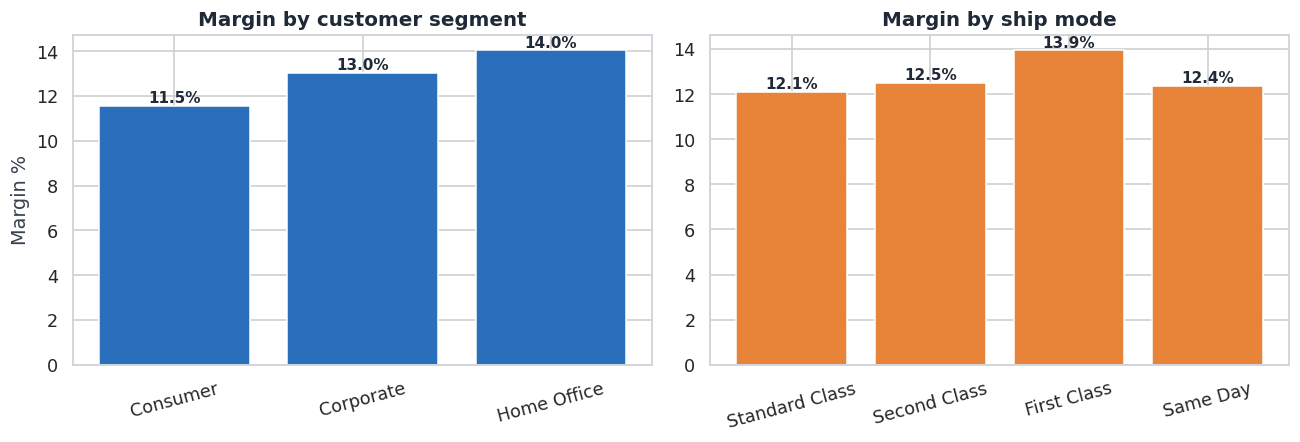

                 Sales    Profit  Margin %
Segment                                   
Consumer     1161401.3  134119.2      11.5
Corporate     706146.4   91979.1      13.0
Home Office   429653.1   60298.7      14.0 

                    Sales    Profit  Margin %
Ship Mode                                    
Standard Class  1358215.7  164088.8      12.1
Second Class     459193.6   57446.6      12.5
First Class      351428.4   48969.8      13.9
Same Day         128363.1   15891.8      12.4


In [14]:
seg = (df.groupby("Segment")[["Sales", "Profit"]].sum().sort_values("Profit", ascending=False))
seg["Margin %"] = seg["Profit"] / seg["Sales"] * 100

ship = (df.groupby("Ship Mode")[["Sales", "Profit"]].sum().sort_values("Profit", ascending=False))
ship["Margin %"] = ship["Profit"] / ship["Sales"] * 100

fig, axes = plt.subplots(1, 2, figsize=(12, 4.2))
axes[0].bar(seg.index, seg["Margin %"], color=C_SALES)
axes[0].set_title("Margin by customer segment")
axes[0].set_ylabel("Margin %")
for i, m in enumerate(seg["Margin %"]):
    axes[0].text(i, m + 0.15, f"{m:.1f}%", ha="center", fontsize=10, fontweight="bold")

axes[1].bar(ship.index, ship["Margin %"], color=C_PROFIT)
axes[1].set_title("Margin by ship mode")
for i, m in enumerate(ship["Margin %"]):
    axes[1].text(i, m + 0.15, f"{m:.1f}%", ha="center", fontsize=10, fontweight="bold")
for a in axes:
    a.tick_params(axis="x", rotation=15)
fig.tight_layout()
save(fig, "fig7_segment_shipmode.png")
plt.show()

print(seg.round(1), "\n")
print(ship.round(1))


In [15]:
# customer concentration: what share of profit comes from the top customers?
cust = df.groupby("Customer ID")["Profit"].sum().sort_values(ascending=False)
top10_share = cust.head(int(len(cust) * 0.1)).sum() / cust.sum() * 100
print(f"Top 10% of customers generate {top10_share:.0f}% of total profit")
print(f"Customers with negative lifetime profit: {(cust < 0).sum()} of {len(cust)}")


Top 10% of customers generate 57% of total profit
Customers with negative lifetime profit: 155 of 793


**Insight 5 — Home Office buyers are the margin sweet spot, and profit is concentrated.**
All three segments are profitable, but Home Office leads on margin (14.0%) despite being the
smallest by sales — a natural target for retention and upsell. Ship-mode margins sit within 2
points of each other (First Class 13.9% to Standard Class 12.1%), so shipping speed is not the
profitability lever. Profit is concentrated: the top 10% of customers generate 57% of it, while
155 of 793 customers are lifetime-unprofitable — and 94% of those unprofitable customers have
bought at a discount of 30% or more.


## 10. Key findings

1. **The business grows but leaks margin.** Sales rebound after a small 2015 dip and grow 20-30%
   a year, but 2017 profit grows only half as fast as sales — profitability quality, not demand,
   is the constraint.
2. **Tables and Bookcases are structurally unprofitable.** Cumulative four-year losses of -$17.7K
   and -$3.5K; no other sub-category is close.
3. **The Central region's weakness is concentrated in Furniture.** Central runs a 7.9% margin
   (vs 14.9% in the West), and its Furniture cell is the only region-category combination in the
   red while its Technology profit is healthy.
4. **Profitability breaks once discounts pass 20%.** Margins are +29.5% at full price, +11.6% at
   11-20% off, then turn negative from 21-30% (-10.0%) and collapse above 40% (-77.4%).
5. **Deep discounts erase nearly half of all profit.** The 13.9% of lines discounted 30% or more
   lost $135K combined — against $286K of total company profit.

## 11. Recommendations

1. **Cap standard discounts at 20%.** Anything deeper needs approval as a deliberate clearance
   decision. This single rule removes most loss-making lines, because margins are already negative
   in the 21-30% band.
2. **Re-price or renegotiate Tables and Bookcases.** If supplier costs cannot come down, exit the
   lines — four years of cumulative losses will not fix themselves with volume.
3. **Target Central-region Furniture first.** Review Central's discount approvals and regional
   pricing before any national policy change.
4. **Protect and grow the Home Office segment** with bundles and loyalty offers — highest margin,
   smallest share of sales.
5. **Redirect promotional spend to Technology and Paper/Accessories**, where margins absorb
   discounts without going negative.

## 12. Conclusion and next steps

Sales growth has masked a slow margin leak. The data points to one dominant cause — discounting
past ~30% — concentrated in specific products and one region, which makes it fixable with targeted
policy rather than a broad overhaul.

Next steps with richer data: model price elasticity per sub-category, run a cohort analysis on
customer retention, and test margin recovery after a discount cap on a single region.

---
*Analysis and code: Youssef Mamdouh. Dataset: Tableau Sample Superstore (fictional sample data
for educational use).*
